In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)


In [8]:
# Load CSV
df = pd.read_csv('datafile.csv') 

df.head()


,State/UT,Area,Ever tobacco users (%),Current tobacco users (%),Ever tobacco smokers (%),Current tobacco smokers (%),Ever cigarette users (%),Current cigarette users (%),Ever bidi users (%),Current bidi users (%),...,Students who noticed cigarette advertisements/promotions at point of sale in past 30 days (%),Students who were taught in class about harmful effects of tobacco use during past 12 months (%),Students who thought it is difficult to quit once someone starts smoking tobacco (%),Students who thought other people’s tobacco smoking is harmful to them (%),Students who favoured ban on smoking inside enclosed public places (%),Students who favoured ban on smoking at outdoor public places (%),"School heads aware of COTPA, 2003 (%)","Schools authorized by the state government to collect fine for violation under Section-6 of the COTPA, 2003 (%)",Schools followed ‘tobacco-free school’ guidelines (%),Schools aware of the policy for displaying ‘tobacco-free school’ board (%)
0,India,Total,18.1,8.5,11.0,7.3,4.6,2.6,4.1,2.1,...,17.5,37.8,26.0,70.6,58.1,60.5,85.4,38.2,82.1,82.5
1,India,Urban,13.5,5.5,8.1,4.5,4.1,2.3,3.7,1.9,...,16.3,34.1,30.1,73.3,64.8,67.4,86.9,36.4,82.4,83.0
2,India,Rural,19.5,9.4,11.8,8.1,4.7,2.6,4.3,2.2,...,17.8,38.9,24.8,69.8,56.1,58.6,84.6,39.2,81.9,82.2
3,Andaman and Nicobar Islands,Total,21.5,4.4,8.8,3.7,4.4,1.3,2.7,1.0,...,21.1,23.4,23.0,69.0,65.0,60.6,88.6,1.1,76.0,67.9
4,Andaman and Nicobar Islands,Urban,13.3,3.4,6.5,2.6,3.7,1.3,2.0,0.7,...,20.2,25.7,26.9,66.6,65.1,60.9,89.1,0.0,85.3,42.5


In [10]:
# Understand the Data Structure

In [14]:
# Shape of dataset
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

# Column names
df.columns

# Data Types and Missing Values
df.info()

Rows: 107, Columns: 59
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 107 entries, 0 to 106
Data columns (total 59 columns):
 #   Column                                                                                                                                 Non-Null Count  Dtype  
---  ------                                                                                                                                 --------------  -----  
 0   State/UT                                                                                                                               107 non-null    object 
 1   Area                                                                                                                                   107 non-null    object 
 2   Ever tobacco users (%)                                                                                                                 107 non-null    float64
 3   Current tobacco users (%)                      

In [16]:
# Data Cleaning

In [18]:
# Convert numeric columns stored as strings
cols_to_convert = [
    'Median age of initiation of Cigarette (in years)',
    'Median age of initiation of Bidi (in years)',
    'Median age of initiation of smokeless tobacco (in years)',
    'Bought Cigarette as individual sticks in past 30 days    (%)',
    'Bought Bidi as individual sticks in past 30 days     (%)',
    'Students who saw anyone using tobacco on mass media in past 30 days  (%)'
]

for col in cols_to_convert:
    df[col] = pd.to_numeric(df[col], errors='coerce')


In [26]:
# Check for nulls
df.isnull().sum()

State/UT                                                                                                                                  0
Area                                                                                                                                      0
Ever tobacco users (%)                                                                                                                    0
Current tobacco users (%)                                                                                                                 0
Ever tobacco smokers (%)                                                                                                                  0
Current tobacco smokers (%)                                                                                                               0
Ever cigarette users (%)                                                                                                                  0
Current cigarette us

In [28]:
# Univariate Analysis (Distributions)

Text(0.5, 1.0, 'Distribution of Current Tobacco Users (%)')

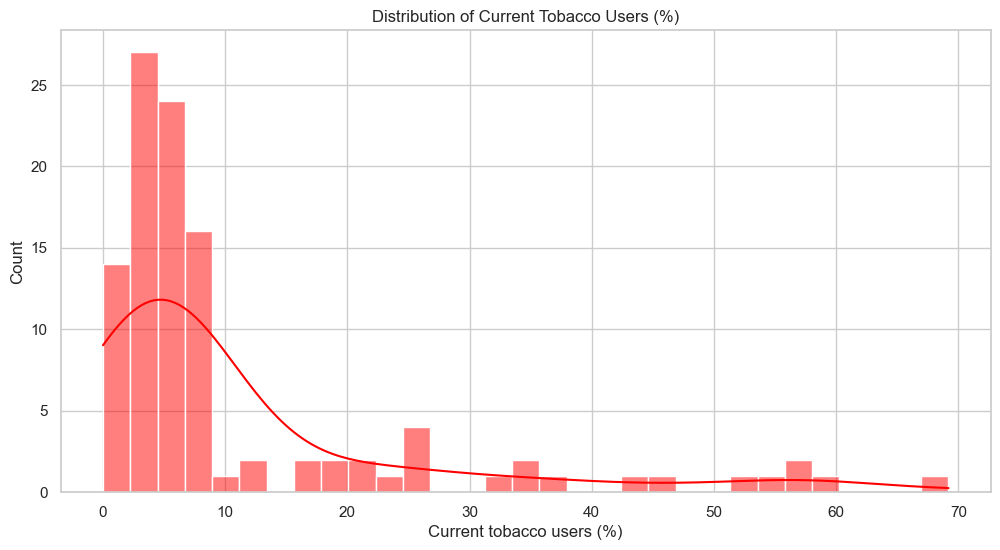

In [30]:
sns.histplot(df['Current tobacco users (%)'], kde=True, color='red')
plt.title('Distribution of Current Tobacco Users (%)')

In [32]:
# Age of Initiation

Text(0.5, 1.0, 'Age of Initiation (Years)')

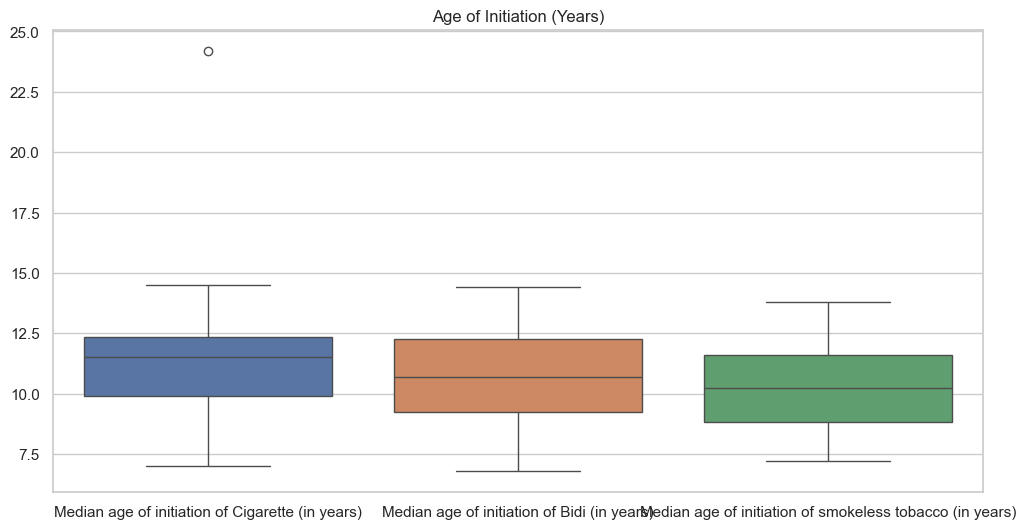

In [34]:
sns.boxplot(data=df[['Median age of initiation of Cigarette (in years)', 
                     'Median age of initiation of Bidi (in years)', 
                     'Median age of initiation of smokeless tobacco (in years)']])
plt.title('Age of Initiation (Years)')


In [36]:
# Bivariate Analysis

Text(0.5, 1.0, 'Urban vs Rural: Tobacco Usage')

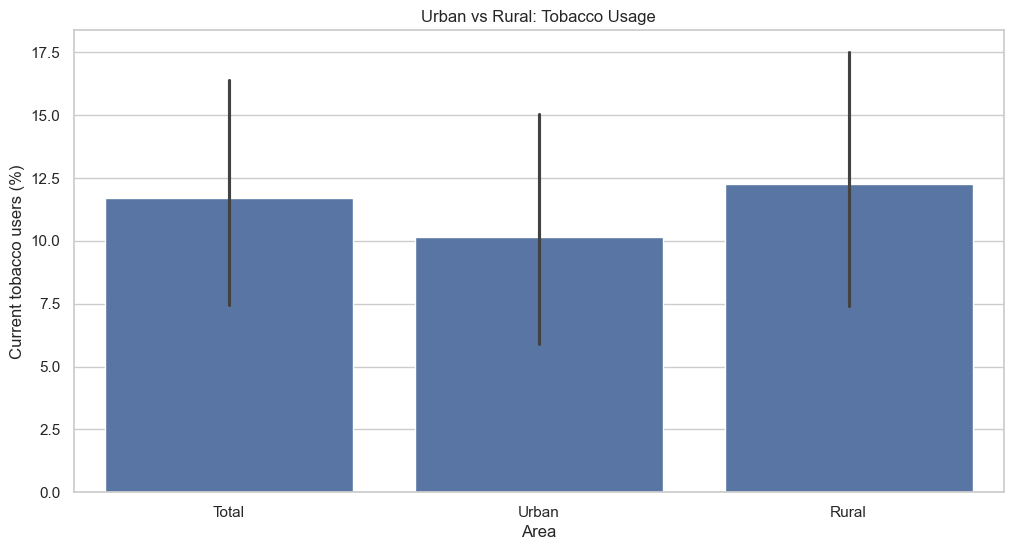

In [38]:
sns.barplot(x='Area', y='Current tobacco users (%)', data=df)
plt.title('Urban vs Rural: Tobacco Usage')


In [40]:
# Correlation Heatmap

Text(0.5, 1.0, 'Correlation Heatmap: Tobacco Usage, Exposure & Awareness')

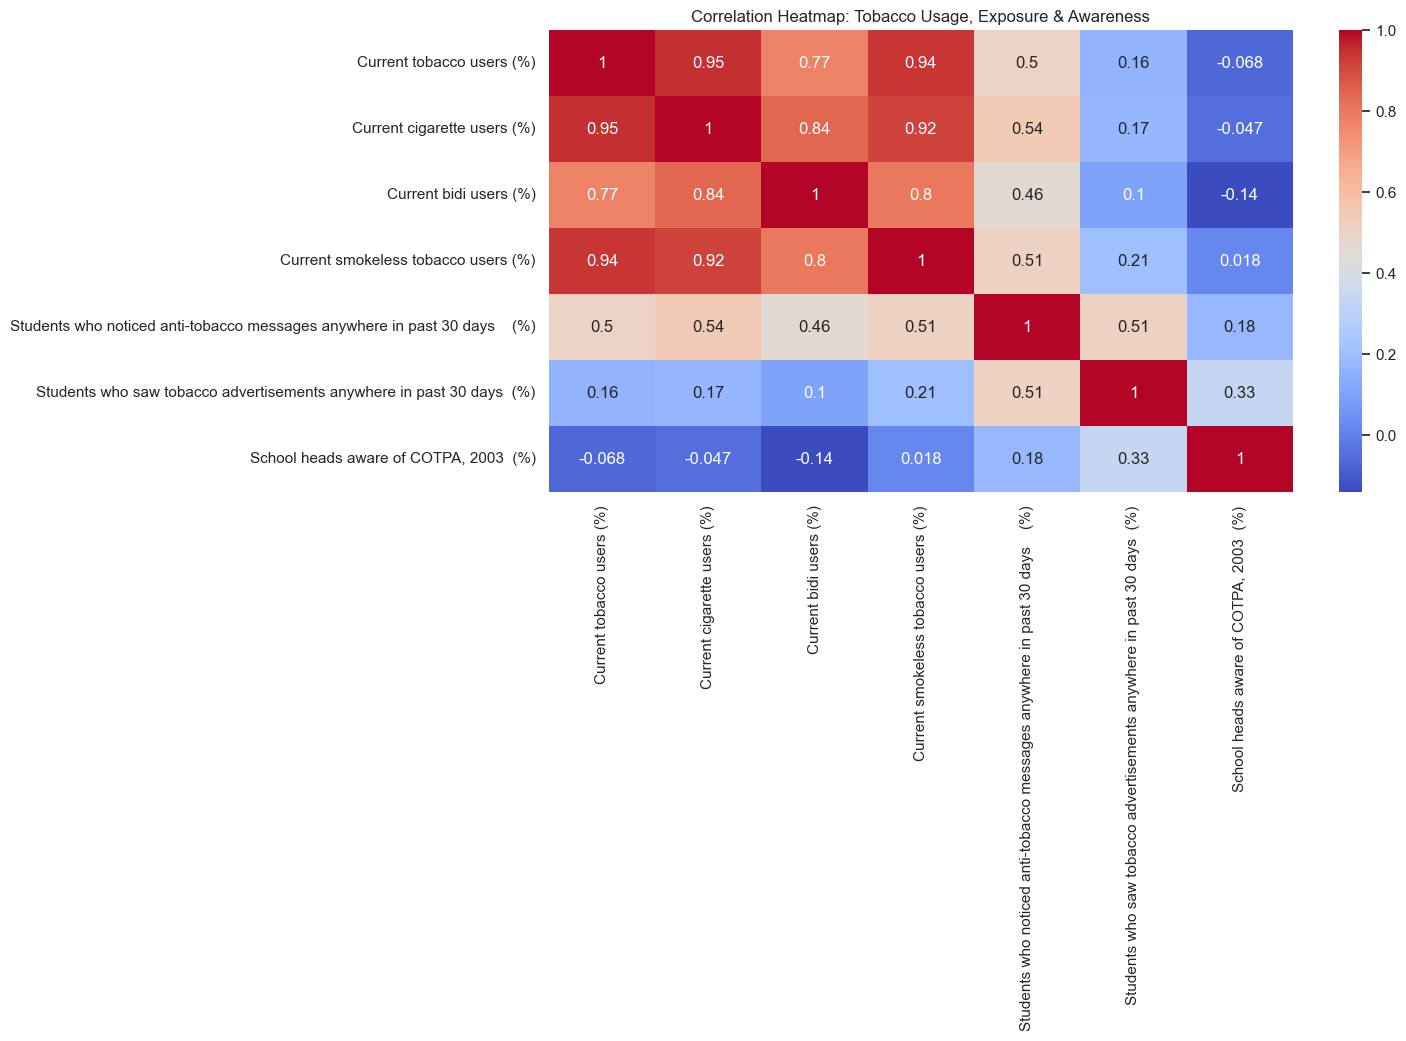

In [42]:
# Select relevant columns
corr_cols = [
    'Current tobacco users (%)',
    'Current cigarette users (%)',
    'Current bidi users (%)',
    'Current smokeless tobacco users (%)',
    'Students who noticed anti-tobacco messages anywhere in past 30 days    (%)',
    'Students who saw tobacco advertisements anywhere in past 30 days  (%)',
    'School heads aware of COTPA, 2003  (%)'
]

# Correlation heatmap
corr = df[corr_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap: Tobacco Usage, Exposure & Awareness')


In [44]:
# Grouped Analysis

Text(0.5, 1.0, 'State-wise Current Tobacco Usage (%)')

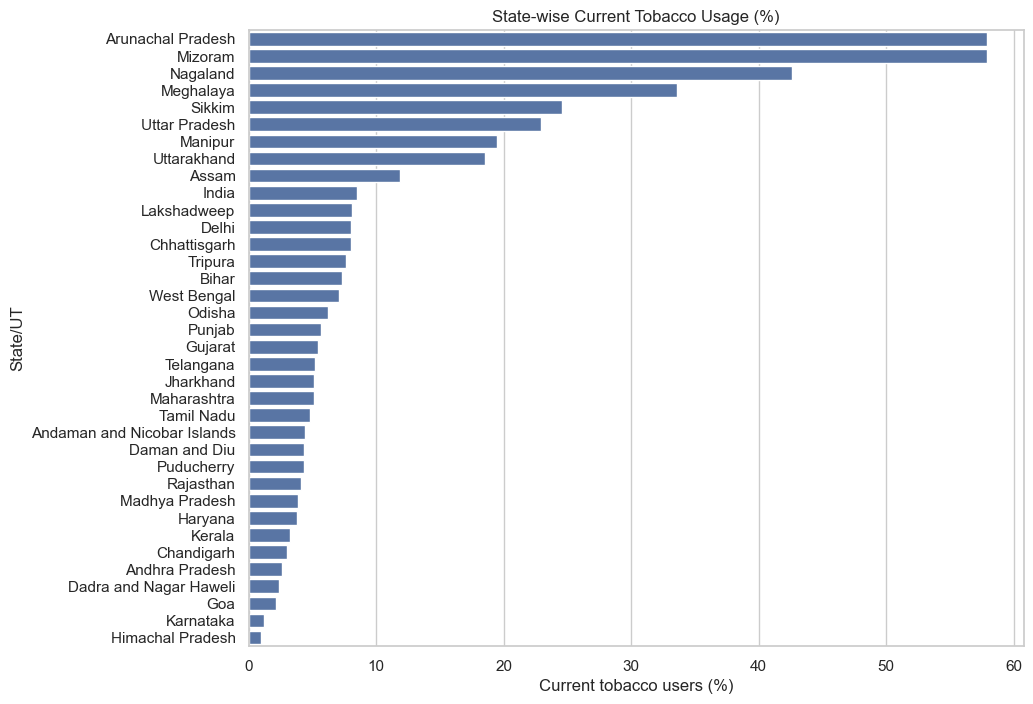

In [46]:
state_usage = df[df['Area'] == 'Total'].sort_values('Current tobacco users (%)', ascending=False)

plt.figure(figsize=(10,8))
sns.barplot(y='State/UT', x='Current tobacco users (%)', data=state_usage)
plt.title('State-wise Current Tobacco Usage (%)')


In [48]:
# Youth Exposure vs Tobacco Usage

Text(0.5, 1.0, 'Youth Exposure to Ads vs Current Tobacco Usage')

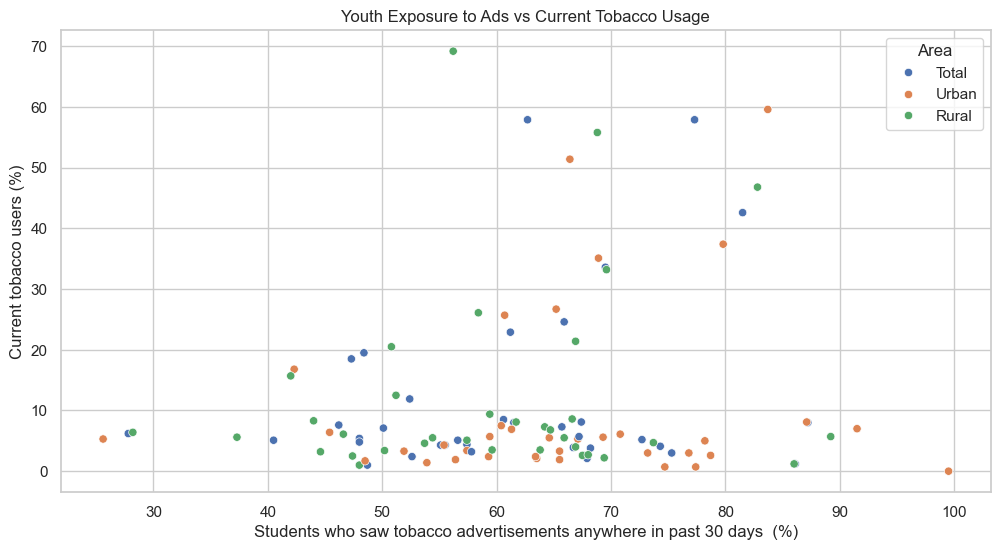

In [50]:
sns.scatterplot(
    x='Students who saw tobacco advertisements anywhere in past 30 days  (%)',
    y='Current tobacco users (%)',
    hue='Area',
    data=df
)
plt.title('Youth Exposure to Ads vs Current Tobacco Usage')


In [52]:
# Outlier Detection

Text(0.5, 1.0, 'Outlier Detection: Current Tobacco Users')

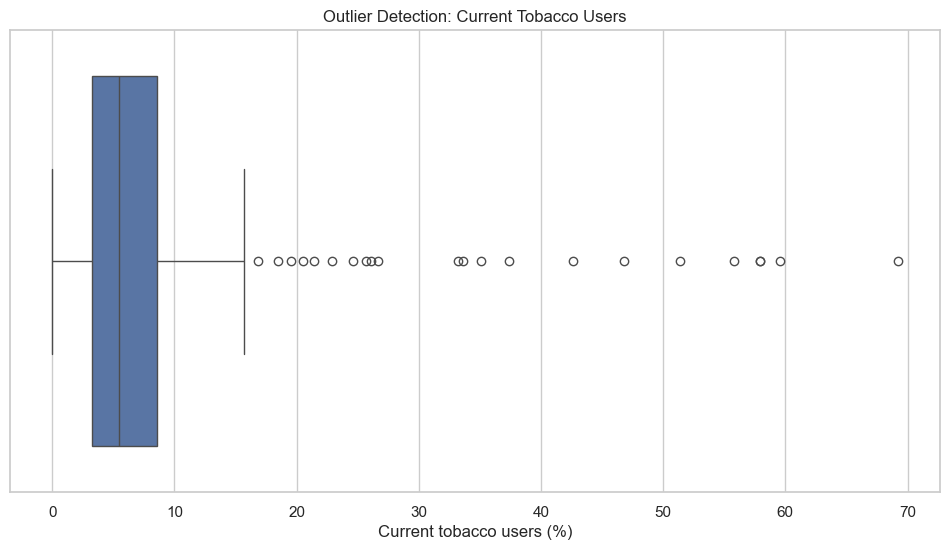

In [54]:
sns.boxplot(x=df['Current tobacco users (%)'])
plt.title('Outlier Detection: Current Tobacco Users')


In [56]:
df.to_csv('cleaned_tobacco_data.csv', index=False)
